In [8]:
import torch
import torch.nn as nn
from torchvision import models, transforms
from torchvision.models import ResNet18_Weights
from torch.utils.data import DataLoader,Dataset
from torchvision.datasets import ImageFolder
import torch.nn.functional as F

import sys
from pathlib import Path
from torchvision import datasets
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import math
from collections import Counter
import pandas as pd

from torch.optim import Adam
from torchvision import transforms
from torchvision.models import resnet18, ResNet18_Weights
from PIL import Image

from sklearn.metrics import classification_report

# Project root
PROJECT_DIR = Path.cwd().parent

if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

sys.path.append("../src")

from data import (
    letterbox,
    create_train_val_datasets,
    create_dataloaders,
    predict_images
)

from models import SimpleCNN

from train import train_model

from utils import (
    get_predictions,
    plot_confusion_matrix,
    get_classification_report,
    plot_training_history,
    set_seed
)
from data import (
    letterbox,
    create_train_val_datasets,
    create_dataloaders
)


In [9]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

UNSEEN_DIR = PROJECT_DIR / "dataset" / "neysan"
TEST_DIR = PROJECT_DIR / "dataset" / "test"
MERGED_TRAIN_DIR = PROJECT_DIR / "dataset" / "merged_train"
CHECKPOINT_PATH = PROJECT_DIR / "checkpoints" /"resnet18_full_finetuning_non_letterbox_best.pt" 



In [10]:
test_transform = transforms.Compose([
    transforms.Lambda(
        lambda img: letterbox(
            img,
            target_size=(224, 224)
        )
    ),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])


test_dataset = ImageFolder(
    TEST_DIR,
    transform=test_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE
)

train_dataset, val_dataset, train_indices, val_indices, class_to_idx = \
    create_train_val_datasets(
        data_dir=MERGED_TRAIN_DIR,
        train_transform = test_transform,
        val_transform=test_transform,
        test_size=0.2,
        seed=7,
    )

train_loader, val_loader = create_dataloaders(
    train_dataset=train_dataset,
    val_dataset=val_dataset,
    batch_size=32,
    shuffle_train=True,
)

full_dataset = datasets.ImageFolder(MERGED_TRAIN_DIR)
class_names = full_dataset.classes

print("Train:", len(train_dataset), "Val:", len(val_dataset))
print("Classes:", class_names)


Train: 2713 Val: 679
Classes: ['ambulance', 'autobus', 'kamyun', 'kamyunet', 'minibus', 'savari', 'taxi', 'vanet']


### Load Model

In [11]:
model = models.resnet18(
    weights=ResNet18_Weights.DEFAULT
)

model.fc = nn.Linear(
    model.fc.in_features,
    8
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model = model.to(DEVICE)

In [12]:
model.eval()

correct = 0
total = 0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total

print("Checkpoint:", CHECKPOINT_PATH)
print("Best Epoch:", checkpoint.get("epoch"))
print("Best Val Accuracy:", checkpoint.get("val_accuracy"))
print("Test Accuracy:", accuracy)

Checkpoint: d:\AI Bootcamp_M Sharif\traffic_vehicle_project\checkpoints\resnet18_full_finetuning_non_letterbox_best.pt
Best Epoch: 122
Best Val Accuracy: 0.9837997054491899
Test Accuracy: 98.5


In [ ]:
correct = 0
total = 0

wrong_predictions = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        outputs = model(images)

        probabilities = torch.softmax(outputs, dim=1)

        confidence, predicted = torch.max(
            probabilities,
            dim=1
        )

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

        for i in range(len(labels)):

            if predicted[i] != labels[i]:

                image_path = test_dataset.samples[
                    total - len(labels) + i
                ][0]

                wrong_predictions.append({
                    "image_path": image_path,
                    "true_class": test_dataset.classes[
                        labels[i].item()
                    ],
                    "predicted_class": test_dataset.classes[
                        predicted[i].item()
                    ],
                    "confidence": confidence[i].item()
                })


accuracy = 100 * correct / total

print("Checkpoint:", CHECKPOINT_PATH)
print("Best Epoch:", checkpoint.get("epoch"))
print("Best Val Accuracy:", checkpoint.get("val_accuracy"))
print("Test Accuracy:", accuracy)

print("Number of wrong predictions:", len(wrong_predictions))

for item in wrong_predictions:
    print(
        item["image_path"],
        "| True:",
        item["true_class"],
        "| Predicted:",
        item["predicted_class"],
        "| Confidence:",
        f'{item["confidence"]:.4f}'
    )

Checkpoint: d:\AI Bootcamp_M Sharif\traffic_vehicle_project\checkpoints\resnet18_full_finetuning_non_letterbox_best.pt
Best Epoch: 122
Best Val Accuracy: 0.9837997054491899
Test Accuracy: 98.5
Number of wrong predictions: 6
d:\AI Bootcamp_M Sharif\traffic_vehicle_project\dataset\test\ambulance\215936132.jpg | True: ambulance | Predicted: vanet | Confidence: 0.9972
d:\AI Bootcamp_M Sharif\traffic_vehicle_project\dataset\test\kamyun\212881811.jpg | True: kamyun | Predicted: kamyunet | Confidence: 0.9954
d:\AI Bootcamp_M Sharif\traffic_vehicle_project\dataset\test\kamyun\215619169.jpg | True: kamyun | Predicted: kamyunet | Confidence: 0.9658
d:\AI Bootcamp_M Sharif\traffic_vehicle_project\dataset\test\kamyun\215662509.jpg | True: kamyun | Predicted: minibus | Confidence: 0.5845
d:\AI Bootcamp_M Sharif\traffic_vehicle_project\dataset\test\kamyun\216034399.jpg | True: kamyun | Predicted: kamyunet | Confidence: 0.9735
d:\AI Bootcamp_M Sharif\traffic_vehicle_project\dataset\test\kamyun\217258

In [14]:
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.activations = None
        self.gradients = None
        target_layer.register_forward_hook(self._save_activation)
        target_layer.register_full_backward_hook(self._save_gradient)

    def _save_activation(self, module, input, output):
        self.activations = output.detach()

    def _save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def generate(self, input_tensor, class_idx=None):
        self.model.zero_grad()
        output = self.model(input_tensor)
        if class_idx is None:
            class_idx = output.argmax(dim=1).item()
        output[:, class_idx].backward()

        pooled_grad = self.gradients.mean(dim=[0, 2, 3])
        activations = self.activations.squeeze(0).clone()
        for i in range(activations.shape[0]):
            activations[i] *= pooled_grad[i]

        heatmap = activations.mean(dim=0).cpu().numpy()
        heatmap = np.maximum(heatmap, 0)
        heatmap = heatmap / (heatmap.max() + 1e-8)
        return heatmap, class_idx


def denormalize(tensor):
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    img = tensor.cpu() * std + mean
    img = img.clamp(0, 1).permute(1, 2, 0).numpy()
    return img


def overlay_heatmap(image_np, heatmap, alpha=0.45):
    heatmap_img = Image.fromarray(np.uint8(heatmap * 255)).resize(
        (image_np.shape[1], image_np.shape[0]), resample=Image.BILINEAR
    )
    heatmap_colored = plt.cm.jet(np.array(heatmap_img) / 255.0)[..., :3]
    return (1 - alpha) * image_np + alpha * heatmap_colored


gradcam = GradCAM(model, model.layer4)


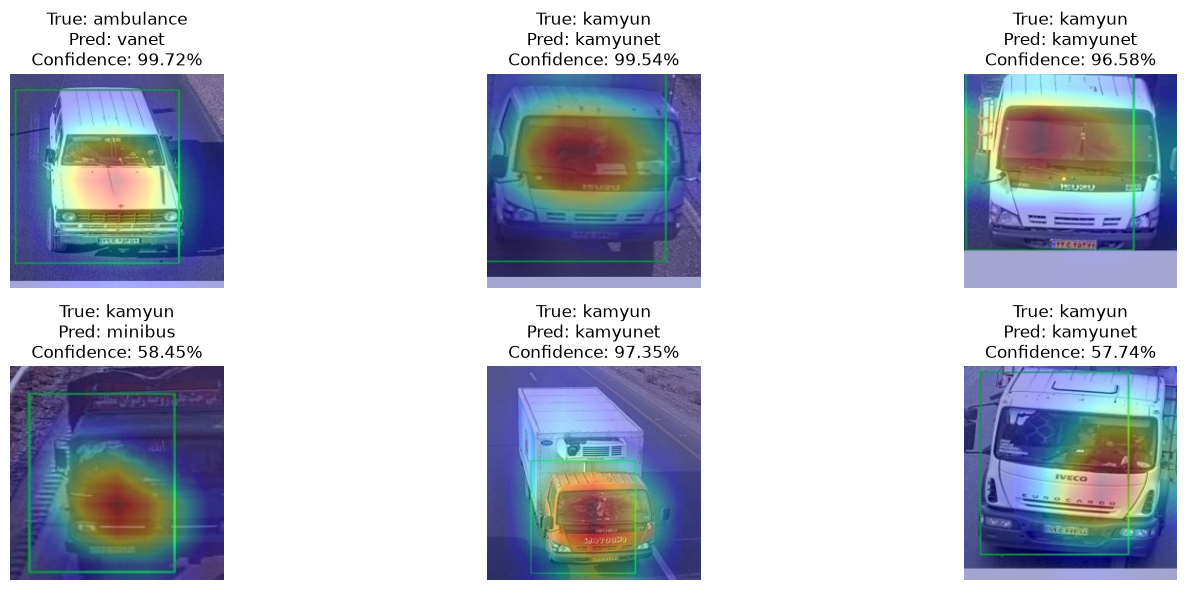

In [20]:
import math
import matplotlib.pyplot as plt
from PIL import Image

n = len(wrong_predictions)

cols = 3
rows = math.ceil(n / cols)

fig, axes = plt.subplots(
    rows,
    cols,
    figsize=(16, 3 * rows )
)

axes = np.array(axes).reshape(-1)

for ax, item in zip(axes, wrong_predictions):

    # -------------------------
    # Load original image
    # -------------------------
    img = Image.open(item["image_path"]).convert("RGB")

    # -------------------------
    # Prepare input
    # -------------------------
    input_tensor = test_transform(img).unsqueeze(0).to(DEVICE)

    # -------------------------
    # Generate Grad-CAM
    # -------------------------
    heatmap, class_idx = gradcam.generate(
        input_tensor
    )

    # -------------------------
    # Convert original image
    # -------------------------
    image_np = np.array(img.resize((224, 224))) / 255.0

    # -------------------------
    # Overlay Grad-CAM
    # -------------------------
    overlay = overlay_heatmap(
        image_np,
        heatmap,
        alpha = 0.35
    )

    # -------------------------
    # Show
    # -------------------------
    ax.imshow(overlay)
    ax.axis("off")

    ax.set_title(
        f'True: {item["true_class"]}\n'
        f'Pred: {item["predicted_class"]}\n'
        f'Confidence: {item["confidence"]:.2%}'
    )

# Hide unused axes
for ax in axes[n:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [16]:
report_full = get_classification_report(
    model=model,
    loader=test_loader,
    class_names=class_names,
    device=DEVICE,
)

              precision    recall  f1-score   support

   ambulance     1.0000    0.9800    0.9899        50
     autobus     1.0000    1.0000    1.0000        50
      kamyun     1.0000    0.9000    0.9474        50
    kamyunet     0.9259    1.0000    0.9615        50
     minibus     0.9804    1.0000    0.9901        50
      savari     1.0000    1.0000    1.0000        50
        taxi     1.0000    1.0000    1.0000        50
       vanet     0.9804    1.0000    0.9901        50

    accuracy                         0.9850       400
   macro avg     0.9858    0.9850    0.9849       400
weighted avg     0.9858    0.9850    0.9849       400



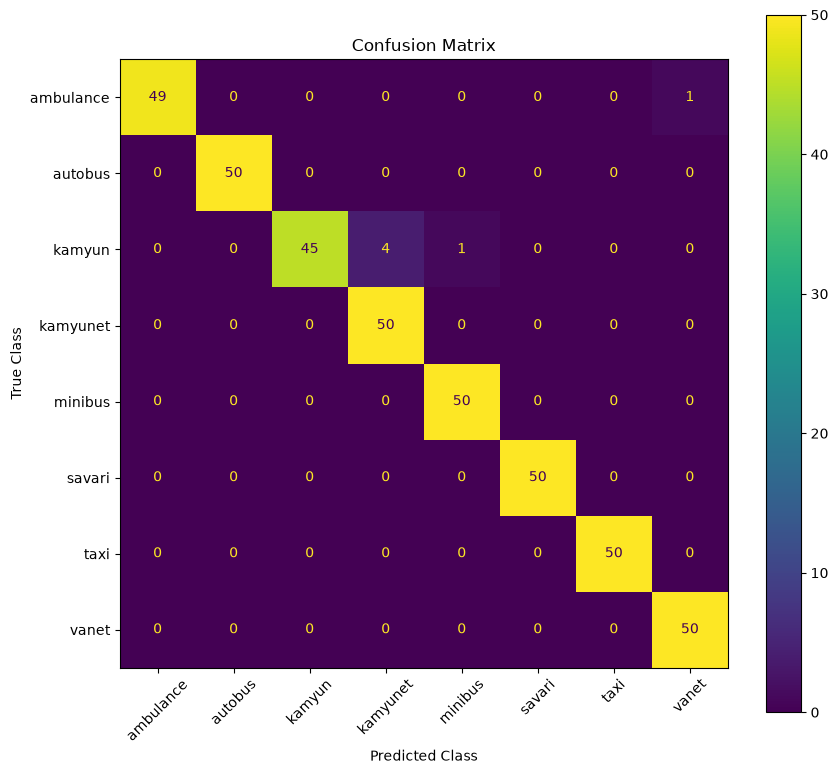

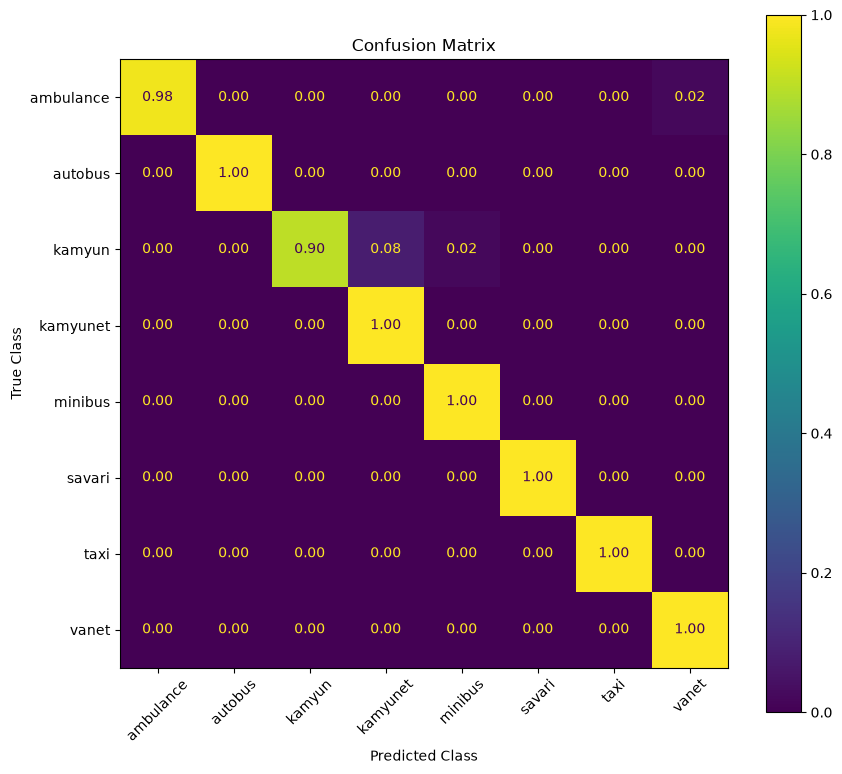

array([[0.98, 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.02],
       [0.  , 1.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  ],
       [0.  , 0.  , 0.9 , 0.08, 0.02, 0.  , 0.  , 0.  ],
       [0.  , 0.  , 0.  , 1.  , 0.  , 0.  , 0.  , 0.  ],
       [0.  , 0.  , 0.  , 0.  , 1.  , 0.  , 0.  , 0.  ],
       [0.  , 0.  , 0.  , 0.  , 0.  , 1.  , 0.  , 0.  ],
       [0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 1.  , 0.  ],
       [0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 1.  ]])

In [17]:
plot_confusion_matrix(model, test_loader, class_names, DEVICE)

plot_confusion_matrix(model, test_loader, class_names, DEVICE, normalize="true")
